In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


Libraries imported successfully!
TensorFlow version: 2.21.0


In [1]:
from google.colab import files
uploaded = files.upload()

Saving train_1.csv to train_1.csv


In [3]:

import pandas as pd

df = pd.read_csv("train_1.csv", nrows=1000)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (1000, 551)


,Page,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,...,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
0,2NE1_zh.wikipedia.org_all-access_spider,18.0,11.0,5.0,13.0,14.0,9.0,9.0,22.0,26.0,...,32.0,63.0,15.0,26.0,14.0,20.0,22.0,19.0,18.0,20.0
1,2PM_zh.wikipedia.org_all-access_spider,11.0,14.0,15.0,18.0,11.0,13.0,22.0,11.0,10.0,...,17.0,42.0,28.0,15.0,9.0,30.0,52.0,45.0,26.0,20.0
2,3C_zh.wikipedia.org_all-access_spider,1.0,0.0,1.0,1.0,0.0,4.0,0.0,3.0,4.0,...,3.0,1.0,1.0,7.0,4.0,4.0,6.0,3.0,4.0,17.0
3,4minute_zh.wikipedia.org_all-access_spider,35.0,13.0,10.0,94.0,4.0,26.0,14.0,9.0,11.0,...,32.0,10.0,26.0,27.0,16.0,11.0,17.0,19.0,10.0,11.0
4,52_Hz_I_Love_You_zh.wikipedia.org_all-access_s...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,48.0,9.0,25.0,13.0,3.0,11.0,27.0,13.0,36.0,10.0


In [4]:

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())

# Check missing values in each row
print("Missing values in first 10 articles:")
print(df.isnull().sum(axis=1).head(10))


Dataset shape: (1000, 551)
Total missing values: 18796
Missing values in first 10 articles:
0      0
1      0
2      0
3      0
4    291
5      0
6    365
7      0
8      0
9      0
dtype: int64


In [5]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Separate page names and daily traffic values
date_columns = df.columns.drop("Page")

traffic = df[date_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Select 5 articles with the fewest missing values
best_rows = traffic.notna().sum(axis=1).nlargest(5).index
traffic_5 = traffic.loc[best_rows].copy()

# Fill missing values using each article's median
traffic_5 = traffic_5.T.fillna(
    traffic_5.median(axis=1)
).T

# Replace remaining missing values with zero
traffic_5 = traffic_5.fillna(0)

# Convert to time-series format: dates × articles
traffic_5 = traffic_5.T

# Normalize values between 0 and 1
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(traffic_5)

print("Cleaned data shape:", traffic_5.shape)
print("Missing values:", traffic_5.isnull().sum().sum())
print("Normalized data shape:", scaled_data.shape)

display(pd.DataFrame(
    scaled_data,
    index=traffic_5.index,
    columns=traffic_5.columns
).head())


Cleaned data shape: (550, 5)
Missing values: 0
Normalized data shape: (550, 5)


,0,1,2,3,5
2015-07-01,0.030801,0.014540,0.004762,0.112583,0.051887
2015-07-02,0.016427,0.019386,0.000000,0.039735,0.028302
2015-07-03,0.004107,0.021002,0.004762,0.029801,0.014151
2015-07-04,0.020534,0.025848,0.004762,0.307947,0.018868
2015-07-05,0.022587,0.014540,0.000000,0.009934,0.089623


In [6]:

import numpy as np

LOOKBACK = 30

X, y = [], []

for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i-LOOKBACK:i])
    y.append(scaled_data[i])

X = np.array(X)
y = np.array(y)

print("Input shape (X):", X.shape)
print("Target shape (y):", y.shape)


Input shape (X): (520, 30, 5)
Target shape (y): (520, 5)


In [7]:

split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training inputs:", X_train.shape)
print("Testing inputs:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training inputs: (416, 30, 5)
Testing inputs: (104, 30, 5)
Training targets: (416, 5)
Testing targets: (104, 5)


In [8]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(64, input_shape=(30, 5)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(5)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,165 (78.77 KB)

 Trainable params: 20,165 (78.77 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("LSTM training completed!")


Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0037 - val_loss: 0.0012
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0035 - val_loss: 0.0011
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0034 - val_loss: 0.0011
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0033 - val_loss: 0.0011
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0032 - val_loss: 0.0011
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0032 - val_loss: 0.0011
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0031 - val_loss: 0.0011
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0031 - val_loss: 0.0011
Epoch 9/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0030 - val_loss: 0.0011
Epoch 10/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0030 - val_loss: 0.0011
Epoch 11/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0029 - val_loss: 0.0011
Epoch 12/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0

In [10]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict test data
y_pred_scaled = model.predict(X_test)

# Convert predictions and actual values to original page-view scale
y_test_actual = scaler.inverse_transform(y_test)
y_pred_actual = scaler.inverse_transform(y_pred_scaled)

# Prevent negative page-view predictions
y_pred_actual = np.maximum(y_pred_actual, 0)

# Calculate evaluation metrics
mae = mean_absolute_error(
    y_test_actual.flatten(),
    y_pred_actual.flatten()
)

rmse = np.sqrt(mean_squared_error(
    y_test_actual.flatten(),
    y_pred_actual.flatten()
))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))


4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 231ms/step
MAE: 12.72
RMSE: 35.78


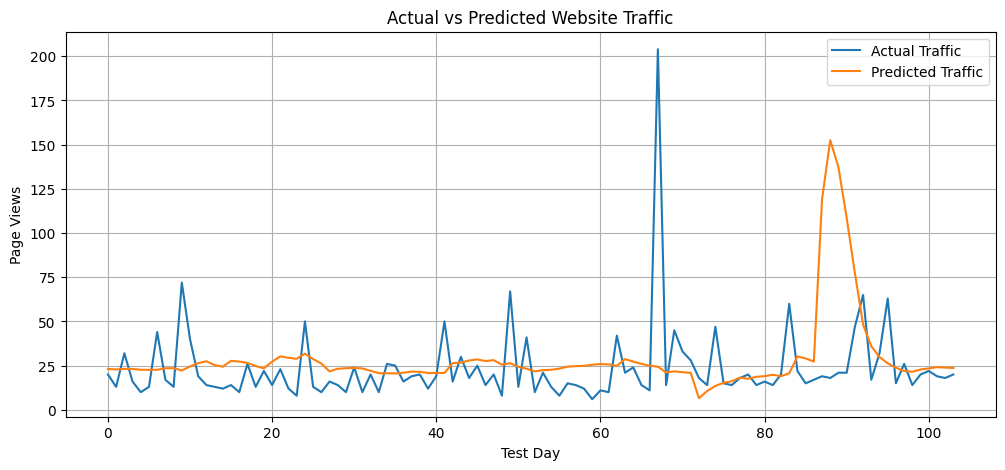

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Plot the first article
plt.plot(
    y_test_actual[:, 0],
    label="Actual Traffic"
)

plt.plot(
    y_pred_actual[:, 0],
    label="Predicted Traffic"
)

plt.title("Actual vs Predicted Website Traffic")
plt.xlabel("Test Day")
plt.ylabel("Page Views")
plt.legend()
plt.grid(True)
plt.show()


In [19]:

last_sequence = scaled_data[-30:].copy()
future_predictions = []

for _ in range(7):
    next_day = model.predict(
        last_sequence[np.newaxis, :, :],
        verbose=0
    )[0]

    future_predictions.append(next_day)

    last_sequence = np.vstack([
        last_sequence[1:],
        next_day
    ])

future_predictions = scaler.inverse_transform(
    np.array(future_predictions)
)

future_predictions = np.maximum(future_predictions, 0)

future_df = pd.DataFrame(
    np.round(future_predictions).astype(int),
    columns=[f"Article {i+1}" for i in range(5)],
    index=[f"Day {i+1}" for i in range(7)]
)

display(future_df)



,Article 1,Article 2,Article 3,Article 4,Article 5
Day 1,27,21,6,21,19
Day 2,27,21,6,20,19
Day 3,27,20,5,20,18
Day 4,26,20,5,19,18
Day 5,26,20,5,19,18
Day 6,26,20,5,19,18
Day 7,25,20,5,19,17


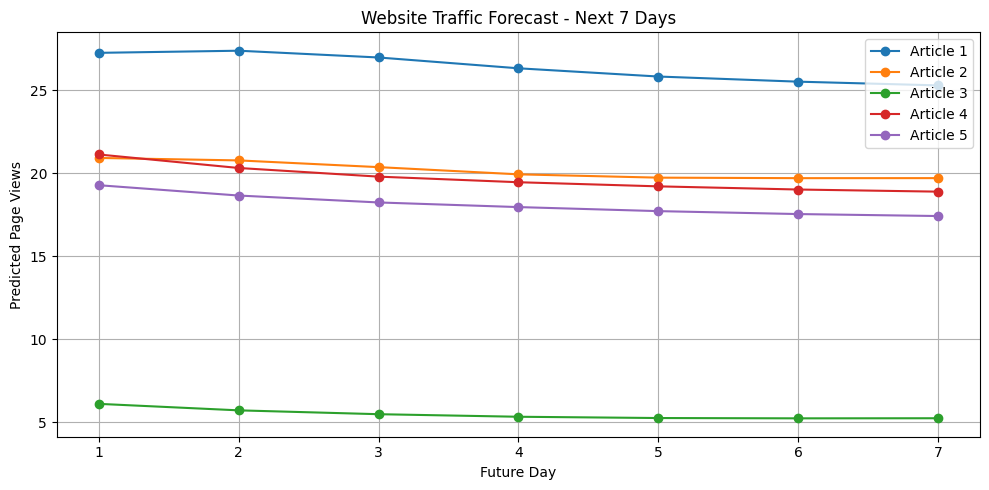

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(5):
    plt.plot(
        range(1, 8),
        future_predictions[:, i],
        marker="o",
        label=f"Article {i+1}"
    )

plt.title("Website Traffic Forecast - Next 7 Days")
plt.xlabel("Future Day")
plt.ylabel("Predicted Page Views")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

print("WEBSITE TRAFFIC FORECASTING - RESULTS")
print("--------------------------------------")
print("Model: LSTM")
print("Lookback window: 30 days")
print("Number of articles: 5")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("Forecast horizon: 7 days")
print("\nFuture traffic predictions:")
display(future_df)


WEBSITE TRAFFIC FORECASTING - RESULTS
--------------------------------------
Model: LSTM
Lookback window: 30 days
Number of articles: 5
MAE: 12.72
RMSE: 35.78
Forecast horizon: 7 days

Future traffic predictions:


,Article 1,Article 2,Article 3,Article 4,Article 5
Day 1,27,21,6,21,19
Day 2,27,21,6,20,19
Day 3,27,20,5,20,18
Day 4,26,20,5,19,18
Day 5,26,20,5,19,18
Day 6,26,20,5,19,18
Day 7,25,20,5,19,17
